# 01 – MetroPT-3 Exploratory Data Analysis
Step 1: load, profile, locate failure event(s), visually confirm them.

In [1]:
import sys, glob
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import config as C
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
C.PLOT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load & schema

In [2]:
path = glob.glob(str(C.DATA_DIR / C.RAW_CSV_GLOB))[0]
raw = pd.read_csv(path)
print('columns:', list(raw.columns))
df = raw.drop(columns=['Unnamed: 0']).assign(timestamp=lambda d: pd.to_datetime(d['timestamp'])).set_index('timestamp')
print('shape:', df.shape)
print('date range:', df.index.min(), '->', df.index.max())
print('monotonic:', df.index.is_monotonic_increasing, '| duplicate timestamps:', df.index.duplicated().sum())
print(); print(df.dtypes)
print(); print('null counts:'); print(df.isna().sum().to_string())

columns: ['Unnamed: 0', 'timestamp', 'TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']


shape: (1516948, 15)
date range: 2020-02-01 00:00:00 -> 2020-09-01 03:59:50
monotonic: True | duplicate timestamps: 0

TP2                float64
TP3                float64
H1                 float64
DV_pressure        float64
Reservoirs         float64
Oil_temperature    float64
Motor_current      float64
COMP               float64
DV_eletric         float64
Towers             float64
MPG                float64
LPS                float64
Pressure_switch    float64
Oil_level          float64
Caudal_impulses    float64
dtype: object

null counts:
TP2                0
TP3                0
H1                 0
DV_pressure        0
Reservoirs         0
Oil_temperature    0
Motor_current      0
COMP               0
DV_eletric         0
Towers             0
MPG                0
LPS                0
Pressure_switch    0
Oil_level          0
Caudal_impulses    0


In [3]:
print('ANALOG sample'); display(df[C.ANALOGUE_COLS].sample(5, random_state=0).sort_index())
print('DIGITAL sample'); display(df[C.DIGITAL_COLS].sample(5, random_state=0).sort_index())
display(df[C.ANALOGUE_COLS].describe().T)
print({c: sorted(df[c].unique().tolist()) for c in C.DIGITAL_COLS})

ANALOG sample


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP
timestamp,,,,,,,,
2020-02-09 07:21:50,-0.012,8.948,8.934,-0.018,8.950,55.600,0.0375,1.0
2020-02-14 07:08:04,-0.012,8.636,8.620,-0.020,8.636,57.275,0.0375,1.0
2020-03-30 15:32:15,-0.020,10.028,10.022,-0.026,10.030,69.600,3.8400,1.0
2020-06-13 05:11:26,-0.016,9.804,9.790,-0.024,9.802,69.750,3.8225,1.0
2020-07-13 12:44:23,-0.012,9.916,9.902,-0.012,9.916,74.400,3.7925,1.0


DIGITAL sample


,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
timestamp,,,,,,,
2020-02-09 07:21:50,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-14 07:08:04,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-03-30 15:32:15,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-06-13 05:11:26,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-07-13 12:44:23,0.0,1.0,1.0,0.0,1.0,1.0,1.0


,count,mean,std,min,25%,50%,75%,max
TP2,1516948.0,1.367826,3.250930,-0.032,-0.014,-0.012,-0.0100,10.676
TP3,1516948.0,8.984611,0.639095,0.730,8.492,8.960,9.4920,10.302
H1,1516948.0,7.568155,3.333200,-0.036,8.254,8.784,9.3740,10.288
DV_pressure,1516948.0,0.055956,0.382402,-0.032,-0.022,-0.020,-0.0180,9.844
Reservoirs,1516948.0,8.985233,0.638307,0.712,8.494,8.960,9.4920,10.300
Oil_temperature,1516948.0,62.644182,6.516261,15.400,57.775,62.700,67.2500,89.050
Motor_current,1516948.0,2.050171,2.302053,0.020,0.040,0.045,3.8075,9.295
COMP,1516948.0,0.836957,0.369405,0.000,1.000,1.000,1.0000,1.000


{'DV_eletric': [0.0, 1.0], 'Towers': [0.0, 1.0], 'MPG': [0.0, 1.0], 'LPS': [0.0, 1.0], 'Pressure_switch': [0.0, 1.0], 'Oil_level': [0.0, 1.0], 'Caudal_impulses': [0.0, 1.0]}


## 2. Sampling cadence
The brief says 1 Hz; the UCI page is inconsistent (1 Hz vs 0.1 Hz). The data tell the truth.

timestamp
10.0    1337521
9.0      128277
12.0      38321
13.0       7988
11.0       4471
21.0         10

gaps > 60 s: 331 | gaps > 1 h: 160 | longest gap (h): 48.0


Text(0, 0.5, 'rows')

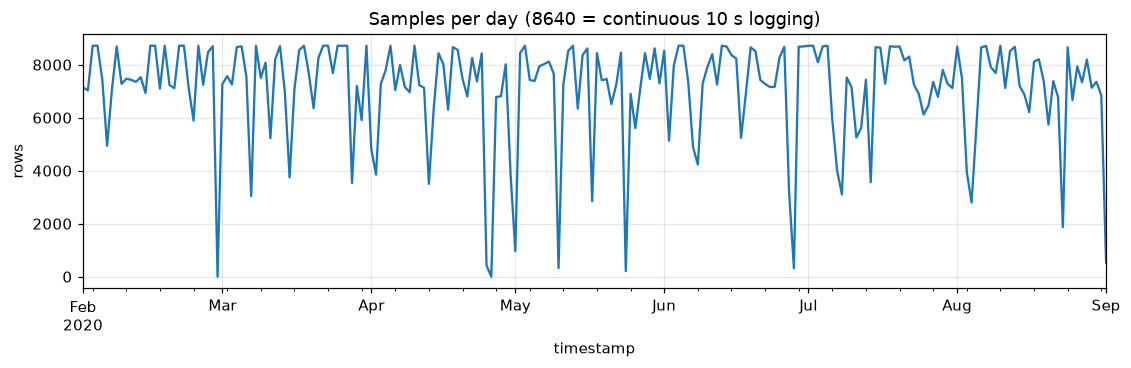

In [4]:
dt = df.index.to_series().diff().dt.total_seconds()
print(dt.value_counts().head(6).to_string())
print('\ngaps > 60 s:', (dt > 60).sum(), '| gaps > 1 h:', (dt > 3600).sum(), '| longest gap (h):', round(dt.max()/3600, 1))
daily_n = df['TP2'].resample('1D').count()
ax = daily_n.plot(figsize=(12, 3), title='Samples per day (8640 = continuous 10 s logging)'); ax.set_ylabel('rows')

## 3. Locate the failure event(s)
There is no label column. The UCI page documents **four** air-leak failures; we check them against the signals.

                start                 end        duration
0 2020-04-18 00:00:00 2020-04-18 23:59:59 0 days 23:59:59
1 2020-05-29 23:30:00 2020-05-30 06:00:00 0 days 06:30:00
2 2020-06-05 10:00:00 2020-06-07 14:30:00 2 days 04:30:00
3 2020-07-15 14:30:00 2020-07-15 19:00:00 0 days 04:30:00


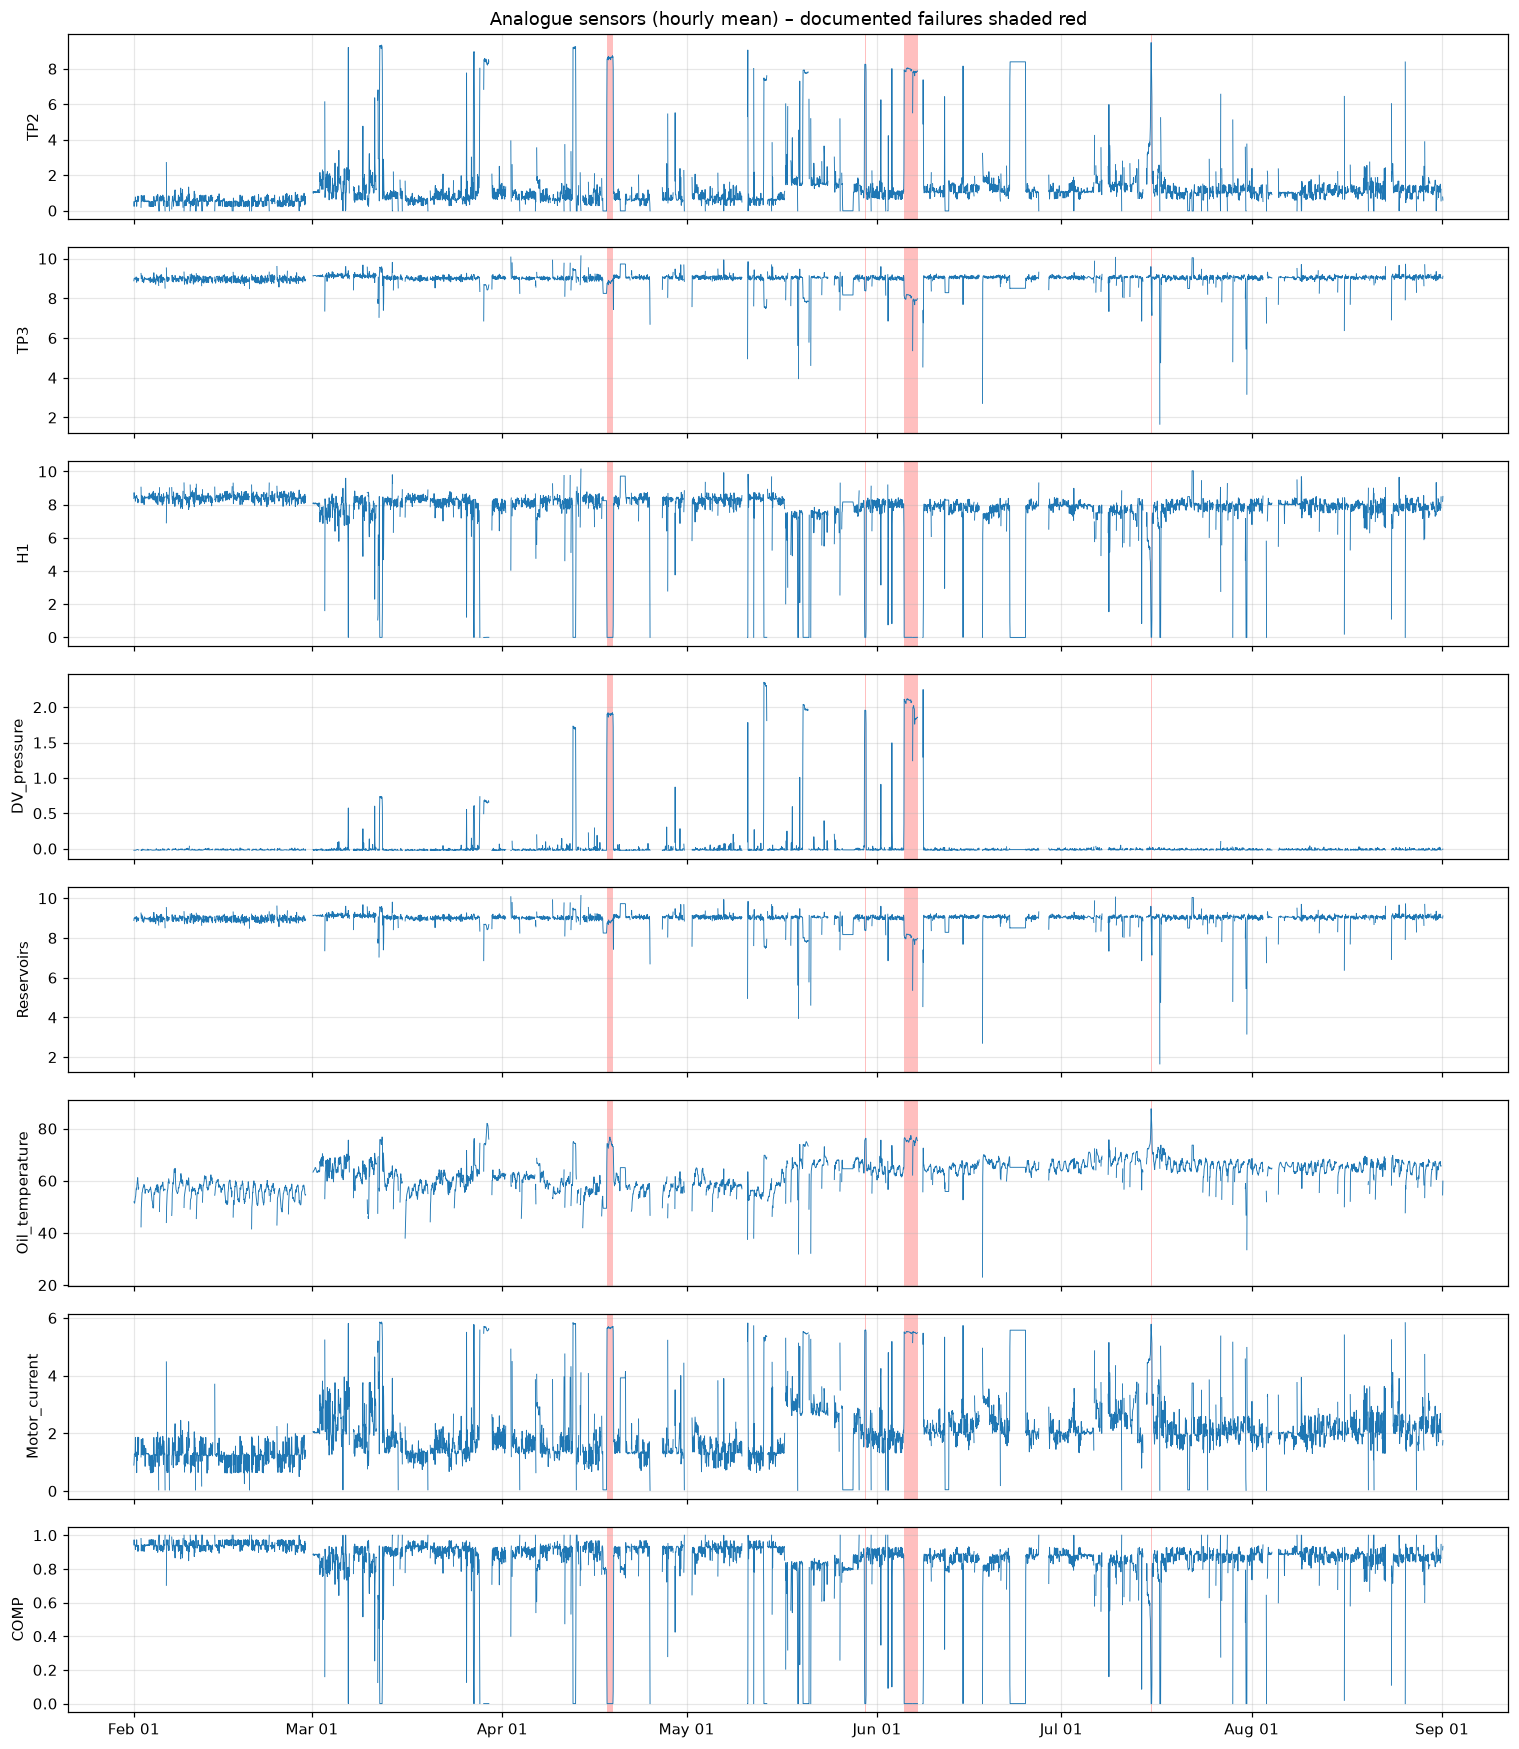

In [5]:
fw = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in C.FAILURE_WINDOWS]
print(pd.DataFrame(fw, columns=['start', 'end']).assign(duration=lambda d: d.end - d.start))

def shade(ax, windows=fw):
    for i, (a, b) in enumerate(windows):
        ax.axvspan(a, b, color='red', alpha=.25, lw=0)
    return ax

# hourly means keep the plot light; hourly max/min preserve spikes
hr = df[C.ANALOGUE_COLS].resample('1h').mean()
fig, axes = plt.subplots(len(C.ANALOGUE_COLS), 1, figsize=(14, 16), sharex=True)
for ax, c in zip(axes, C.ANALOGUE_COLS):
    ax.plot(hr.index, hr[c], lw=.6); shade(ax); ax.set_ylabel(c)
axes[0].set_title('Analogue sensors (hourly mean) – documented failures shaded red')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
fig.tight_layout(); fig.savefig(C.PLOT_DIR / 'eda_analog_overview.png'); plt.show()

### Zoom on each failure (±3 days, raw 10 s data)

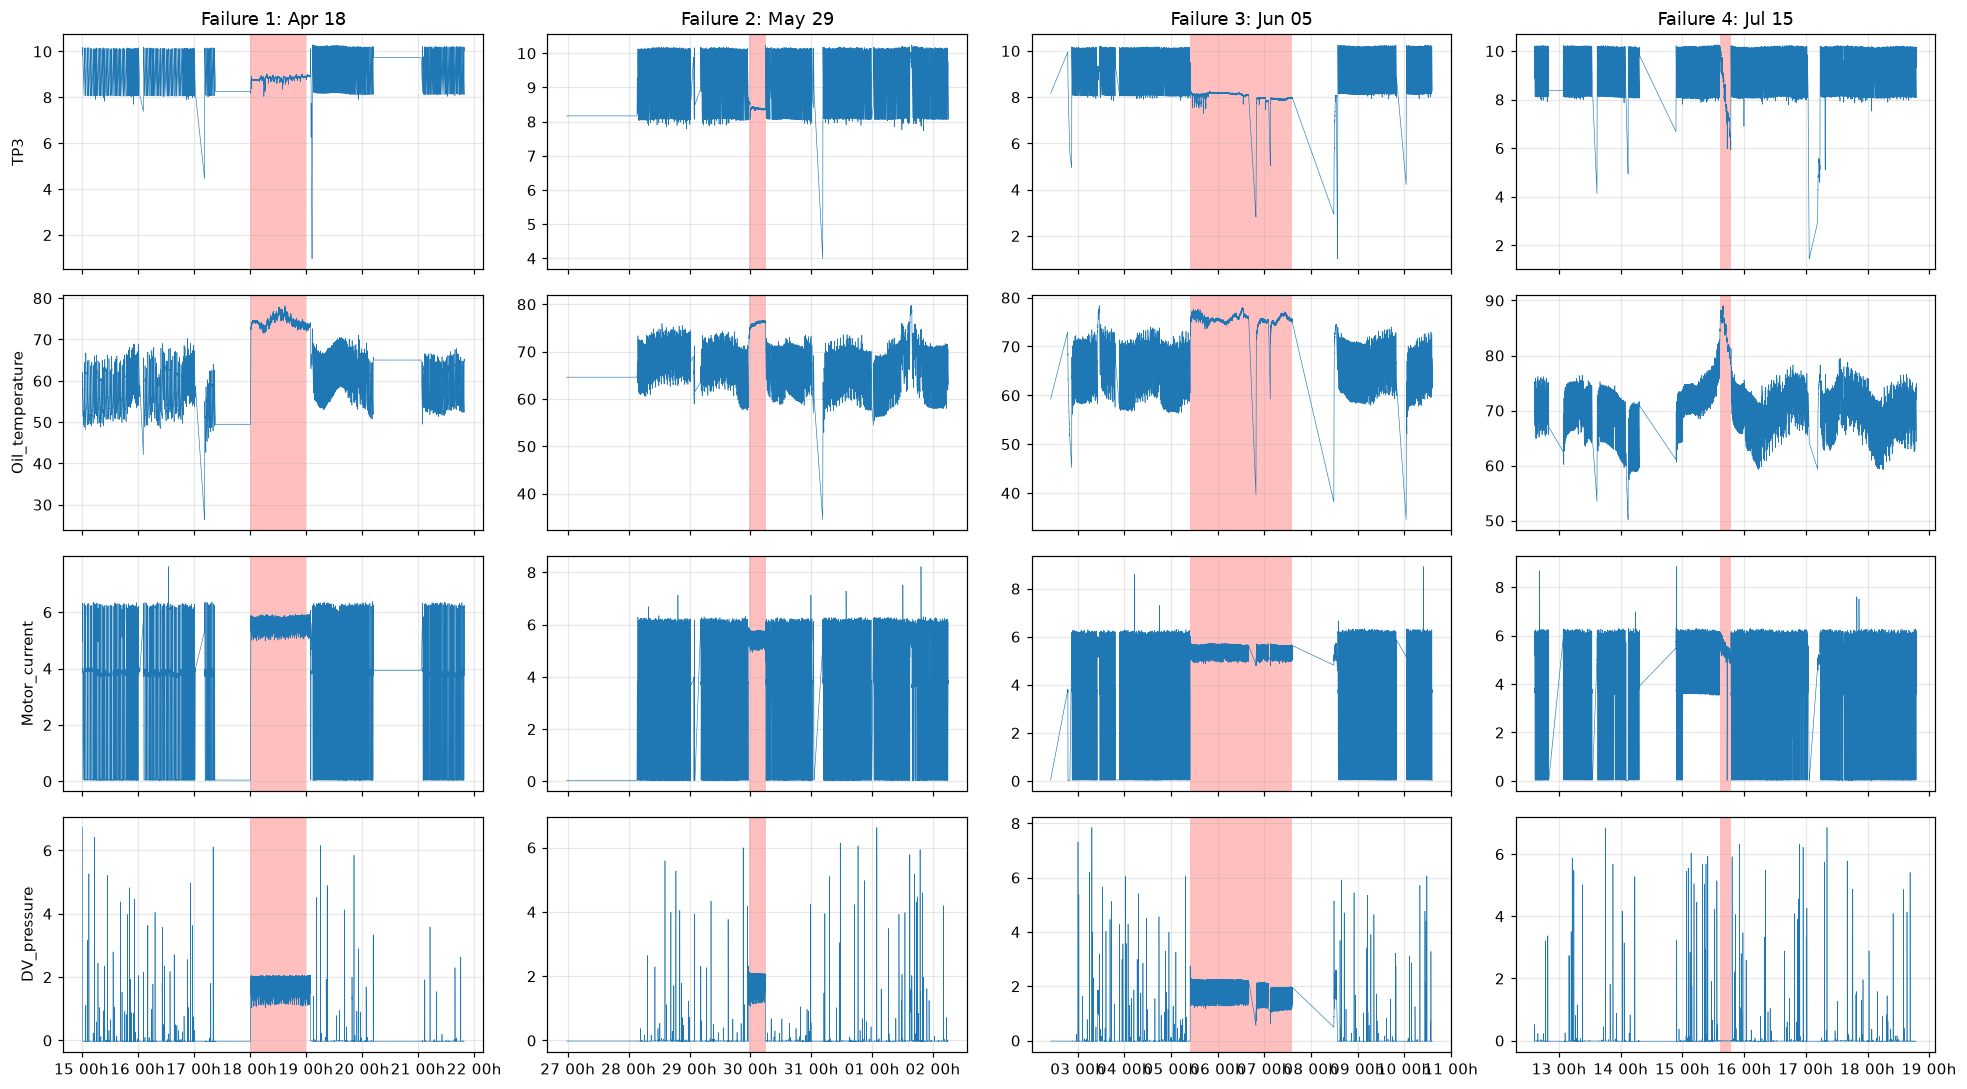

In [6]:
show = ['TP3', 'Oil_temperature', 'Motor_current', 'DV_pressure']
fig, axes = plt.subplots(len(show), len(fw), figsize=(18, 10), sharex='col')
for j, (a, b) in enumerate(fw):
    seg = df.loc[a - pd.Timedelta(days=3): b + pd.Timedelta(days=3)]
    for i, c in enumerate(show):
        ax = axes[i, j]; ax.plot(seg.index, seg[c], lw=.4); ax.axvspan(a, b, color='red', alpha=.25, lw=0)
        if j == 0: ax.set_ylabel(c)
        if i == 0: ax.set_title(f'Failure {j+1}: {a:%b %d}')
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %Hh'))
fig.tight_layout(); fig.savefig(C.PLOT_DIR / 'eda_failure_zoom.png'); plt.show()

### Signature check: duty-cycle indicators per day
A leak makes the compressor run continuously loaded (high motor current, MPG ≈ 0, Towers ≈ 0.5, hot oil).

Days with sustained continuous-load signature:


,rows,Motor_current,Oil_temp,MPG,Towers,TP3_min
timestamp,,,,,,
2020-03-29,7199,5.632,77.241,0.000,0.501,8.360
2020-04-12,7125,4.147,67.834,0.361,0.681,3.768
2020-04-18,8663,5.604,74.131,0.008,0.501,8.038
2020-05-20,7462,5.400,73.503,0.026,0.512,3.908
2020-06-06,7343,5.497,75.402,0.000,0.501,2.816
2020-06-07,4888,5.481,75.464,0.000,0.501,5.026
2020-06-23,7159,5.575,65.150,0.000,0.798,8.506
2020-06-24,7162,5.575,65.150,0.000,0.800,8.506


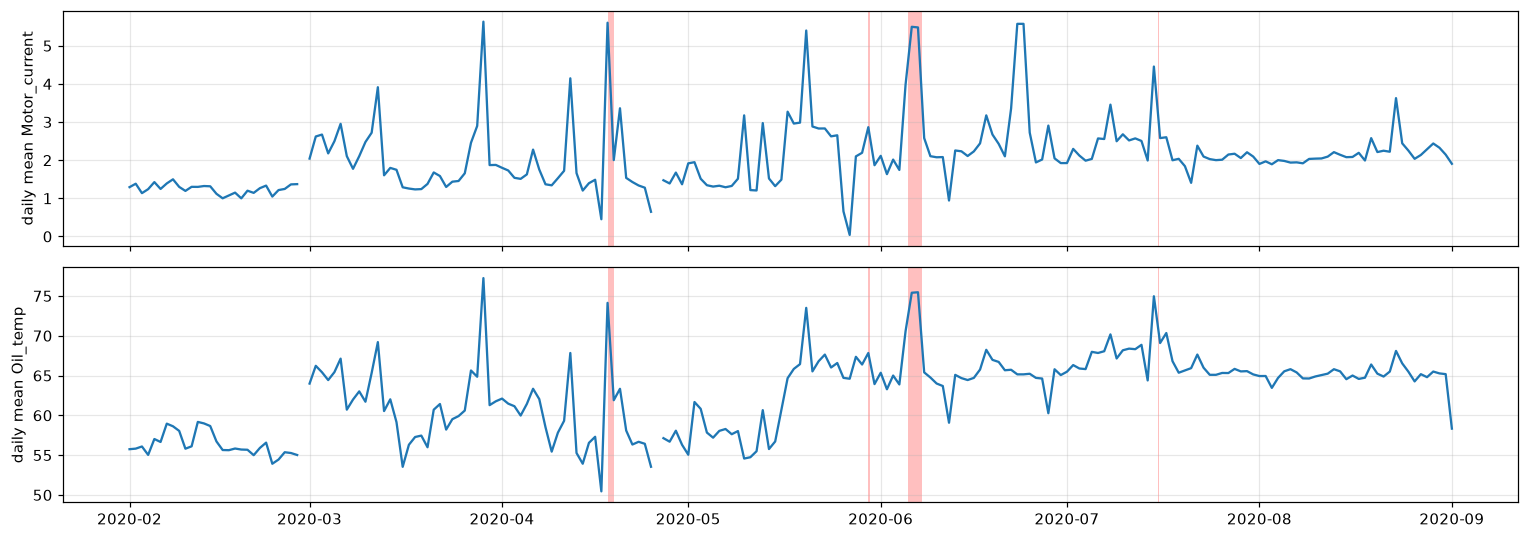

In [7]:
g = df.resample('1D')
daily = pd.DataFrame({'rows': g['TP2'].count(), 'Motor_current': g['Motor_current'].mean(), 'Oil_temp': g['Oil_temperature'].mean(),
                      'MPG': g['MPG'].mean(), 'Towers': g['Towers'].mean(), 'TP3_min': g['TP3'].min()})
flag = daily[(daily.Motor_current > 4) & (daily.MPG < .4)]
print('Days with sustained continuous-load signature:'); display(flag.round(3))
fig, ax = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
ax[0].plot(daily.Motor_current); ax[0].set_ylabel('daily mean Motor_current'); shade(ax[0])
ax[1].plot(daily.Oil_temp); ax[1].set_ylabel('daily mean Oil_temp'); shade(ax[1])
fig.tight_layout(); fig.savefig(C.PLOT_DIR / 'eda_daily_signature.png'); plt.show()

## 4. Data-quality issues to handle in preprocessing

In [8]:
# flat-lined (frozen) sensors, e.g. around Jun 23-24 and May 27
std_day = df[C.ANALOGUE_COLS].resample('1D').std()
frozen = std_day[(std_day['TP3'] < 1e-6)].index.date
print('days with frozen TP3 (std ~ 0):', list(frozen))
print('days with <50% of nominal rows (<4320):', int((daily.rows < 4320).sum()), 'of', len(daily))

days with frozen TP3 (std ~ 0): [datetime.date(2020, 5, 27), datetime.date(2020, 6, 23), datetime.date(2020, 6, 24)]
days with <50% of nominal rows (<4320): 23 of 214


In [9]:
# digital sensors: fraction of time active
display(df[C.DIGITAL_COLS].mean().round(3).to_frame('fraction_active').T)

,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
fraction_active,0.161,0.92,0.833,0.003,0.991,0.904,0.937
